# Polynomial Ridge regression



## Purpose

Test whether degree-two curvature and pairwise interactions improve prediction for unseen geometries compared with the simpler baselines. The validation set is used only after training-only alpha selection.


In [1]:
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_PATH = PROJECT_ROOT / "data" / "prepared" / "train.csv"
VALIDATION_PATH = PROJECT_ROOT / "data" / "prepared" / "validation.csv"
PREDICTIONS_PATH = PROJECT_ROOT / "results" / "predictions.csv"
METRICS_PATH = PROJECT_ROOT / "results" / "validation_metrics.csv"
CV_PATH = PROJECT_ROOT / "results" / "cv_model_selection.csv"
MODEL_PATH = PROJECT_ROOT / "results" / "models" / "polynomial_ridge.joblib"

MODEL_NAME = "polynomial_ridge"
FEATURE_NAMES = [
    "AoA",
    "IB_Flap_Deflection",
    "OB_Flap_Deflection",
    "IB_Flap_Gap_Multiplier",
    "OB_Flap_Gap_Multiplier",
    "IB_Slat_Deflection",
    "OB_Slat_Deflection",
    "IB_Slat_Gap_Multiplier",
    "OB_Slat_Gap_Multiplier",
]
TARGET_NAMES = ["cl", "cd", "cm"]
ALPHA_GRID = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100, 1000]
PREDICTION_COLUMNS = [
    "case_id", "GeoID", "AoA", "split", "model", "target",
    "actual", "predicted", "error", "absolute_error", "squared_error",
]
METRIC_COLUMNS = [
    "model", "target", "scope", "AoA", "n_rows",
    "n_geometries", "MAE", "RMSE", "R2",
]
CV_COLUMNS = ["model", "target", "candidate", "mean_cv_RMSE", "std_cv_RMSE", "selected"]

def make_pipeline(alpha):
    return Pipeline([
        ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha, fit_intercept=True)),
    ])

def alpha_label(alpha):
    return f"alpha={alpha:g}"

## Load prepared data

In [2]:
train = pd.read_csv(TRAIN_PATH)
validation = pd.read_csv(VALIDATION_PATH)
predictions_before = pd.read_csv(PREDICTIONS_PATH)
metrics_before = pd.read_csv(METRICS_PATH)
cv_before = pd.read_csv(CV_PATH) if CV_PATH.exists() else pd.DataFrame(columns=CV_COLUMNS)

required_columns = ["case_id", "GeoID", *FEATURE_NAMES, *TARGET_NAMES]
assert len(train) == 1_260 and len(validation) == 180
assert set(required_columns).issubset(train.columns)
assert set(required_columns).issubset(validation.columns)
assert train[required_columns].notna().all().all()
assert validation[required_columns].notna().all().all()
assert set(train["GeoID"]).isdisjoint(validation["GeoID"])
assert train.groupby("GeoID").size().eq(10).all()
assert list(predictions_before.columns) == PREDICTION_COLUMNS
assert list(metrics_before.columns) == METRIC_COLUMNS
assert list(cv_before.columns) == CV_COLUMNS

previous_predictions_before = predictions_before.loc[
    ~predictions_before["model"].eq(MODEL_NAME)
].reset_index(drop=True)
previous_metrics_before = metrics_before.loc[
    ~metrics_before["model"].eq(MODEL_NAME)
].reset_index(drop=True)
previous_cv_before = cv_before.loc[~cv_before["model"].eq(MODEL_NAME)].reset_index(drop=True)

display(pd.DataFrame({
    "split": ["train", "validation"],
    "rows": [len(train), len(validation)],
    "geometries": [train["GeoID"].nunique(), validation["GeoID"].nunique()],
    "AoA values": [train["AoA"].nunique(), validation["AoA"].nunique()],
}))


,split,rows,geometries,AoA values
0,train,1260,126,10
1,validation,180,18,10



## Model setup

Each target has its own Pipeline: degree-two polynomial expansion, StandardScaler, then Ridge regression with an intercept.

### Model equation

The degree-two feature vector contains all nine inputs, nine squares, and 36 pairwise interactions:

$$
\boldsymbol{\phi}(\mathbf{x})
=\left[x_1,\ldots,x_9,\;x_1^2,\ldots,x_9^2,\;(x_jx_k)_{1\leq j<k\leq9}\right]
$$

This notation groups the term types; the Pipeline determines their column order. For each target:

$$
\hat y(\mathbf{x})=b+\mathbf{w}^{T}\tilde{\boldsymbol{\phi}}(\mathbf{x})
$$

Here, $\tilde{\boldsymbol{\phi}}$ contains the 54 polynomial features standardized using training-fitted means and scales, $b$ is the intercept, and $\mathbf{w}$ contains the coefficients.

### Fitting objective

$$
\underset{b,\mathbf{w}}{\operatorname{minimize}}
\sum_{i=1}^{N}(y_i-\hat y_i)^2
+\alpha\sum_{j=1}^{54}w_j^2
$$

Here, $N$ is the number of training cases and $\alpha$ is the Ridge penalty selected by grouped CV. The intercept is not penalized.

The saved run used Python 3.10.20 and scikit-learn 1.7.2.



## Cross-validation

Five-fold GroupKFold uses `GeoID` as the group, so every geometry’s ten AoA rows stay together. The same folds and alpha grid are used for all targets. Polynomial expansion and scaling are fitted inside each fold. Fold SD is the population SD of the five held-out RMSE values.


In [3]:
X_train = train.loc[:, FEATURE_NAMES]
groups = train["GeoID"]
group_cv = GroupKFold(n_splits=5)
cv_splits = list(group_cv.split(X_train, groups=groups))

held_out_geometry_counts = Counter()
held_out_row_counts = Counter()
fold_summary = []
for fold_number, (fit_indices, holdout_indices) in enumerate(cv_splits, start=1):
    fit_geometries = set(groups.iloc[fit_indices])
    holdout_geometries = set(groups.iloc[holdout_indices])
    assert fit_geometries.isdisjoint(holdout_geometries)
    for geometry in holdout_geometries:
        held_out_geometry_counts[geometry] += 1
        held_out_row_counts[geometry] += int((groups.iloc[holdout_indices] == geometry).sum())
    fold_summary.append({
        "fold": fold_number,
        "fit rows": len(fit_indices),
        "held-out rows": len(holdout_indices),
        "fit geometries": len(fit_geometries),
        "held-out geometries": len(holdout_geometries),
    })

assert len(cv_splits) == 5
assert set(held_out_geometry_counts) == set(groups)
assert all(count == 1 for count in held_out_geometry_counts.values())
assert all(count == 10 for count in held_out_row_counts.values())
assert set(validation["GeoID"]).isdisjoint(held_out_geometry_counts)
display(pd.DataFrame(fold_summary))

,fold,fit rows,held-out rows,fit geometries,held-out geometries
0,1,1000,260,100,26
1,2,1010,250,101,25
2,3,1010,250,101,25
3,4,1010,250,101,25
4,5,1010,250,101,25


### Select the Ridge penalty

In [4]:
cv_records = []
temporary_fold_scores = {}
cv_pipeline_fit_sizes = []

for target in TARGET_NAMES:
    y_target = train[target]
    for alpha in ALPHA_GRID:
        fold_rmses = []
        for fit_indices, holdout_indices in cv_splits:
            candidate_pipeline = make_pipeline(alpha)
            candidate_pipeline.fit(X_train.iloc[fit_indices], y_target.iloc[fit_indices])
            holdout_prediction = candidate_pipeline.predict(X_train.iloc[holdout_indices])
            fold_rmses.append(
                root_mean_squared_error(y_target.iloc[holdout_indices], holdout_prediction)
            )
            cv_pipeline_fit_sizes.append(
                int(candidate_pipeline.named_steps["scaler"].n_samples_seen_)
            )
        temporary_fold_scores[(target, alpha)] = fold_rmses
        cv_records.append({
            "model": MODEL_NAME,
            "target": target,
            "candidate": alpha_label(alpha),
            "alpha": alpha,
            "mean_cv_RMSE": np.mean(fold_rmses),
            "std_cv_RMSE": np.std(fold_rmses, ddof=0),
        })

cv_working = pd.DataFrame(cv_records)
selected_alpha = (
    cv_working.loc[cv_working.groupby("target")["mean_cv_RMSE"].idxmin()]
    .set_index("target")["alpha"]
    .reindex(TARGET_NAMES)
    .to_dict()
)
cv_working["selected"] = cv_working.apply(
    lambda row: row["alpha"] == selected_alpha[row["target"]], axis=1
)
current_cv_rows = cv_working.loc[:, CV_COLUMNS]
updated_cv = pd.concat([previous_cv_before, current_cv_rows], ignore_index=True).loc[:, CV_COLUMNS]
updated_cv.to_csv(CV_PATH, index=False)
saved_cv = pd.read_csv(CV_PATH)

selection_display = cv_working.loc[cv_working["selected"], [
    "target", "alpha", "mean_cv_RMSE", "std_cv_RMSE"
]].reset_index(drop=True)
display(selection_display)

assert len(cv_pipeline_fit_sizes) == len(TARGET_NAMES) * len(ALPHA_GRID) * 5
assert all(size < len(train) for size in cv_pipeline_fit_sizes)
assert not saved_cv.duplicated(["model", "target", "candidate"]).any()
for target in TARGET_NAMES:
    chosen = cv_working.loc[
        cv_working["target"].eq(target) & cv_working["selected"], "mean_cv_RMSE"
    ].iloc[0]
    assert np.isclose(chosen, cv_working.loc[
        cv_working["target"].eq(target), "mean_cv_RMSE"
    ].min())


,target,alpha,mean_cv_RMSE,std_cv_RMSE
0,cl,0.1,0.079320,0.002624
1,cd,1.0,0.019953,0.000744
2,cm,1.0,0.083237,0.003132



## Fit the selected configuration

One fresh Pipeline per target is fitted on all 1,260 training rows using the selected alpha.


In [5]:
final_pipelines = {}
train_predictions = {}
validation_predictions = {}

for target in TARGET_NAMES:
    final_pipeline = make_pipeline(selected_alpha[target])
    final_pipeline.fit(X_train, train[target])
    final_pipelines[target] = final_pipeline
    train_predictions[target] = final_pipeline.predict(X_train)
    validation_predictions[target] = final_pipeline.predict(validation.loc[:, FEATURE_NAMES])

model_bundle = {
    "model_name": MODEL_NAME,
    "feature_names": FEATURE_NAMES,
    "target_names": TARGET_NAMES,
    "selected_alpha": selected_alpha,
    "pipelines": final_pipelines,
}
joblib.dump(model_bundle, MODEL_PATH)

print("Selected alphas:", selected_alpha)

reloaded_bundle = joblib.load(MODEL_PATH)
for target in TARGET_NAMES:
    assert np.allclose(
        reloaded_bundle["pipelines"][target].predict(X_train),
        train_predictions[target],
    )
    assert np.allclose(
        reloaded_bundle["pipelines"][target].predict(validation.loc[:, FEATURE_NAMES]),
        validation_predictions[target],
    )


Selected alphas: {'cl': 0.1, 'cd': 1.0, 'cm': 1.0}



## Validation metrics

Training and validation predictions use the shared long format. Metrics are calculated from the saved validation rows.


In [6]:
def make_prediction_rows(frame, predicted_by_target, split_name):
    rows = []
    for target in TARGET_NAMES:
        target_rows = frame.loc[:, ["case_id", "GeoID", "AoA"]].copy()
        target_rows["split"] = split_name
        target_rows["model"] = MODEL_NAME
        target_rows["target"] = target
        target_rows["actual"] = frame[target].to_numpy()
        target_rows["predicted"] = predicted_by_target[target]
        target_rows["error"] = target_rows["predicted"] - target_rows["actual"]
        target_rows["absolute_error"] = target_rows["error"].abs()
        target_rows["squared_error"] = target_rows["error"].pow(2)
        rows.append(target_rows.loc[:, PREDICTION_COLUMNS])
    return pd.concat(rows, ignore_index=True)

polynomial_prediction_rows = pd.concat([
    make_prediction_rows(train, train_predictions, "train"),
    make_prediction_rows(validation, validation_predictions, "validation"),
], ignore_index=True)
updated_predictions = pd.concat(
    [previous_predictions_before, polynomial_prediction_rows], ignore_index=True
).loc[:, PREDICTION_COLUMNS]
updated_predictions.to_csv(PREDICTIONS_PATH, index=False)
saved_predictions = pd.read_csv(PREDICTIONS_PATH)

def metric_record(rows, target, scope, aoa=np.nan):
    actual = rows["actual"].to_numpy()
    predicted = rows["predicted"].to_numpy()
    return {
        "model": MODEL_NAME,
        "target": target,
        "scope": scope,
        "AoA": aoa,
        "n_rows": len(rows),
        "n_geometries": rows["GeoID"].nunique(),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": root_mean_squared_error(actual, predicted),
        "R2": r2_score(actual, predicted),
    }

def metrics_from_saved_predictions(saved_model_rows):
    records = []
    for target in TARGET_NAMES:
        target_rows = saved_model_rows.loc[saved_model_rows["target"].eq(target)]
        records.append(metric_record(target_rows, target, "overall"))
        for aoa, aoa_rows in target_rows.groupby("AoA", sort=True):
            records.append(metric_record(aoa_rows, target, "per_aoa", aoa))
    return pd.DataFrame(records, columns=METRIC_COLUMNS)

saved_polynomial_validation = saved_predictions.loc[
    saved_predictions["model"].eq(MODEL_NAME)
    & saved_predictions["split"].eq("validation")
].copy()
polynomial_metrics = metrics_from_saved_predictions(saved_polynomial_validation)
updated_metrics = pd.concat(
    [previous_metrics_before, polynomial_metrics], ignore_index=True
).loc[:, METRIC_COLUMNS]
updated_metrics.to_csv(METRICS_PATH, index=False)
saved_metrics = pd.read_csv(METRICS_PATH)

display(saved_metrics.loc[
    saved_metrics["model"].eq(MODEL_NAME) & saved_metrics["scope"].eq("overall"),
    ["target", "n_rows", "n_geometries", "MAE", "RMSE", "R2"],
].reset_index(drop=True))

assert not saved_predictions.duplicated(["case_id", "split", "model", "target"]).any()
assert not saved_metrics.duplicated(["model", "target", "scope", "AoA"]).any()
pd.testing.assert_frame_equal(
    saved_metrics.loc[saved_metrics["model"].eq(MODEL_NAME)].sort_values(
        ["target", "scope", "AoA"]
    ).reset_index(drop=True),
    metrics_from_saved_predictions(saved_polynomial_validation).sort_values(
        ["target", "scope", "AoA"]
    ).reset_index(drop=True),
    check_dtype=False, rtol=1e-12, atol=1e-12,
)


,target,n_rows,n_geometries,MAE,RMSE,R2
0,cl,180,18,0.063269,0.081532,0.940554
1,cd,180,18,0.015438,0.020679,0.975039
2,cm,180,18,0.053314,0.073929,0.877576


## Validation plots

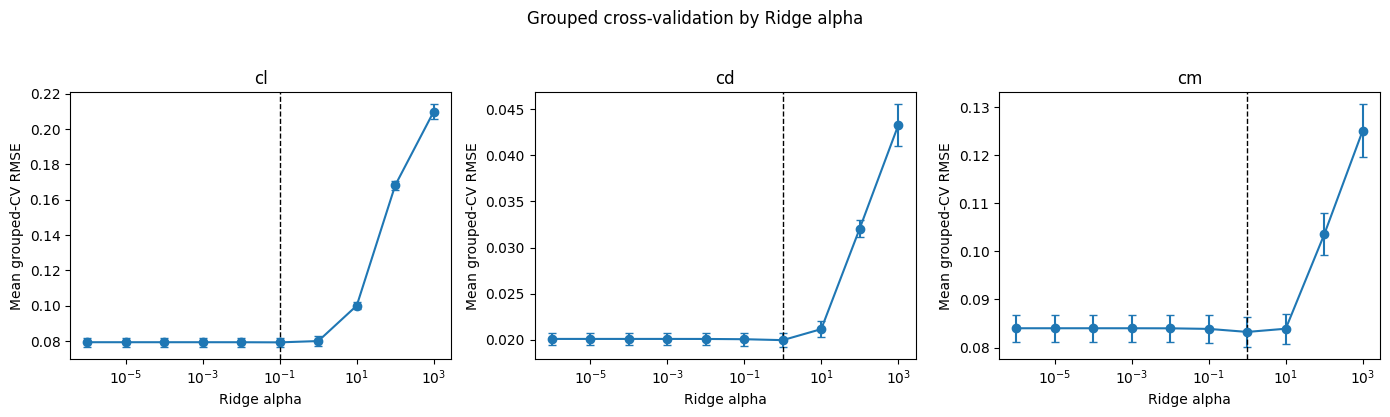

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, target in zip(axes, TARGET_NAMES):
    target_cv = cv_working.loc[cv_working["target"].eq(target)].sort_values("alpha")
    axis.errorbar(
        target_cv["alpha"], target_cv["mean_cv_RMSE"],
        yerr=target_cv["std_cv_RMSE"], marker="o", capsize=3,
    )
    axis.axvline(selected_alpha[target], color="black", linestyle="--", linewidth=1)
    axis.set_xscale("log")
    axis.set_title(target)
    axis.set_xlabel("Ridge alpha")
    axis.set_ylabel("Mean grouped-CV RMSE")
fig.suptitle("Grouped cross-validation by Ridge alpha", y=1.03)
fig.tight_layout()
plt.show()

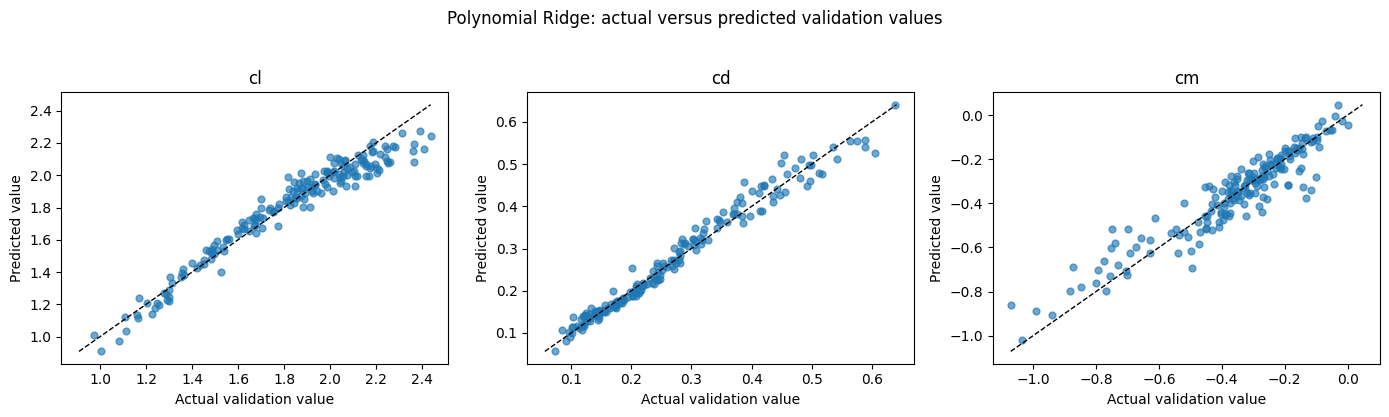

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, target in zip(axes, TARGET_NAMES):
    target_rows = saved_polynomial_validation.loc[saved_polynomial_validation["target"].eq(target)]
    axis.scatter(target_rows["actual"], target_rows["predicted"], alpha=0.65, s=24)
    limits = [
        min(target_rows["actual"].min(), target_rows["predicted"].min()),
        max(target_rows["actual"].max(), target_rows["predicted"].max()),
    ]
    axis.plot(limits, limits, color="black", linestyle="--", linewidth=1)
    axis.set_title(target)
    axis.set_xlabel("Actual validation value")
    axis.set_ylabel("Predicted value")
fig.suptitle("Polynomial Ridge: actual versus predicted validation values", y=1.03)
fig.tight_layout()
plt.show()

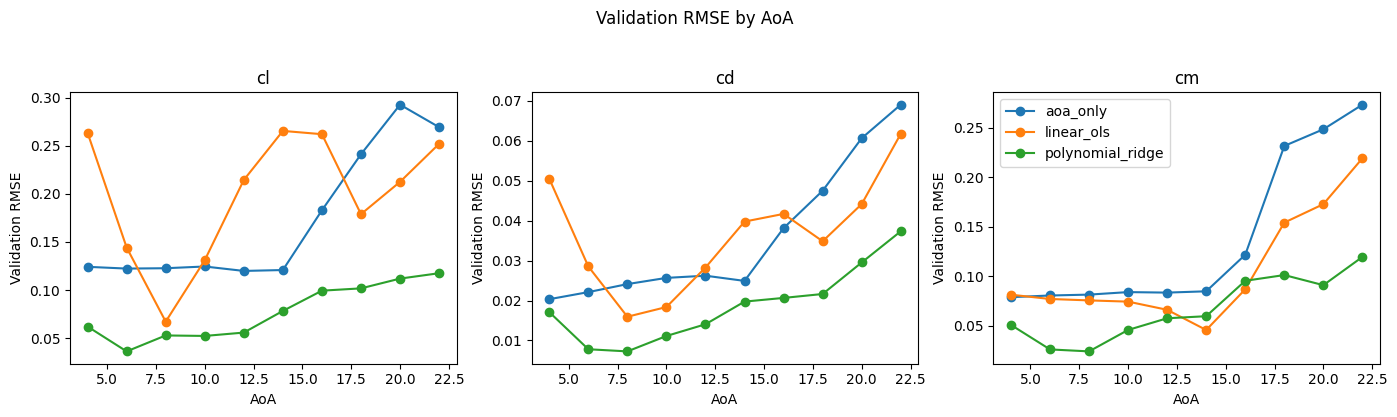

In [9]:
per_aoa_comparison = saved_metrics.loc[
    saved_metrics["model"].isin(["aoa_only", "linear_ols", MODEL_NAME])
    & saved_metrics["scope"].eq("per_aoa")
].copy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for axis, target in zip(axes, TARGET_NAMES):
    for model_name in ["aoa_only", "linear_ols", MODEL_NAME]:
        rows = per_aoa_comparison.loc[
            per_aoa_comparison["target"].eq(target)
            & per_aoa_comparison["model"].eq(model_name)
        ].sort_values("AoA")
        axis.plot(rows["AoA"], rows["RMSE"], marker="o", label=model_name)
    axis.set_title(target)
    axis.set_xlabel("AoA")
    axis.set_ylabel("Validation RMSE")
axes[-1].legend()
fig.suptitle("Validation RMSE by AoA", y=1.03)
fig.tight_layout()
plt.show()


## Model comparison

The table compares overall validation results with the AoA-only and linear OLS baselines. Lower MAE and RMSE are better; higher R² is better.


In [10]:
comparison = (
    saved_metrics.loc[
        saved_metrics["model"].isin(["aoa_only", "linear_ols", MODEL_NAME])
        & saved_metrics["scope"].eq("overall"),
        ["target", "model", "MAE", "RMSE", "R2"],
    ]
    .assign(
        target=lambda frame: pd.Categorical(frame["target"], TARGET_NAMES, ordered=True),
        model=lambda frame: pd.Categorical(
            frame["model"], ["aoa_only", "linear_ols", MODEL_NAME], ordered=True
        ),
    )
    .sort_values(["target", "model"])
)
display(comparison.reset_index(drop=True))

,target,model,MAE,RMSE,R2
0,cl,aoa_only,0.142320,0.184291,0.696275
1,cl,linear_ols,0.178400,0.209156,0.608787
2,cl,polynomial_ridge,0.063269,0.081532,0.940554
3,cd,aoa_only,0.029068,0.039513,0.908863
4,cd,linear_ols,0.031666,0.038803,0.912110
5,cd,polynomial_ridge,0.015438,0.020679,0.975039
6,cm,aoa_only,0.117285,0.156525,0.451207
7,cm,linear_ols,0.086190,0.118004,0.688085
8,cm,polynomial_ridge,0.053314,0.073929,0.877576



## Short conclusion

Polynomial Ridge improves all three targets over both earlier baselines. The selected alphas are 0.1 for `cl` and 1 for `cd` and `cm`. 



## Save results

The notebook writes `results/predictions.csv`, `results/validation_metrics.csv`, `results/cv_model_selection.csv`, and `results/models/polynomial_ridge.joblib`. Reruns replace only `polynomial_ridge` rows.
